# Model revision and post-hoc tests (exercise 04; 12P)

Christoph Grieder & Andreas Hund  
2025-11-13

## Get stared with the data from Exercise 03

We use the same shovelomics example as in Lecture 06, Exercise 03 in order to model the residual variance. Set the work directory (Not needed to load the data as it is retrieved from the web repository). The targeted trait, we aim to evaluate is the silage dry matter yield (DMY) measured in (dt/ha).

Set your working directory, if needed

In [1]:
#R version 4.0.3
#rm(list=ls())   ##always clear workspace before starting!
#setwd("YOUR_PATH")
getwd()

[1] "/home/jovyan/assignments/Ex4/Ex4_Submit"

Load packages

In [2]:
library(tidyverse)
library(lmerTest) #loads lme4 as dependent package
library(emmeans)
#install.packages("MESS")
#library(MESS) #needed for the wallyplot
library(multcomp)
library(lme4)
library(desplot) #used for ggdesplot

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: lme4

Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack



Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step


Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'

Loading required pac

You can add options to executable code like this

Read data from web repository

In [3]:
library(httr) #this and the code bellow is needed to bypass the SSL certificate.
url <- "https://edu.usys.ethz.ch/statdat/DelleyDef.txt"
txt <- content(GET(url, config(ssl_verifypeer = FALSE)), "text")
Data <- read.table(text = txt, sep = "\t", skip = 5, header = TRUE)
str(Data)

'data.frame':	216 obs. of  13 variables:
 $ Site     : chr  "Delley" "Delley" "Delley" "Delley" ...
 $ NLevel   : chr  "H" "H" "H" "H" ...
 $ SubPlot  : int  1 2 3 4 5 6 7 8 9 10 ...
 $ MainPlot : int  1 1 1 1 1 1 1 1 1 1 ...
 $ Replicate: int  1 1 1 1 1 1 1 1 1 1 ...
 $ Entry    : int  5 26 25 4 11 12 15 3 14 17 ...
 $ Genotype : chr  "F98902 x UH007" "N25 x UH007" "N6 x UH007" "EC169 x UH007" ...
 $ Row      : int  1 2 3 4 5 6 1 2 3 4 ...
 $ Range    : int  1 1 1 1 1 1 2 2 2 2 ...
 $ B111     : int  1 1 2 2 3 3 1 1 2 2 ...
 $ B112     : int  1 1 1 1 1 1 1 1 1 1 ...
 $ B121     : int  1 1 2 2 3 3 1 1 2 2 ...
 $ DMY      : num  161 137 134 154 142 ...


Define Factors

In [4]:
Factors <- c("Site", "NLevel", "Replicate", "MainPlot", "SubPlot", "Entry", "Genotype", "Range", "Row")
Data<-Data %>% mutate(across(Factors, as.factor))
str(Data)

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `across(Factors, as.factor)`.
Caused by warning:
! Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(Factors)

  # Now:
  data %>% select(all_of(Factors))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


'data.frame':	216 obs. of  13 variables:
 $ Site     : Factor w/ 1 level "Delley": 1 1 1 1 1 1 1 1 1 1 ...
 $ NLevel   : Factor w/ 2 levels "H","L": 1 1 1 1 1 1 1 1 1 1 ...
 $ SubPlot  : Factor w/ 216 levels "1","2","3","4",..: 1 2 3 4 5 6 7 8 9 10 ...
 $ MainPlot : Factor w/ 6 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ Replicate: Factor w/ 3 levels "1","2","3": 1 1 1 1 1 1 1 1 1 1 ...
 $ Entry    : Factor w/ 36 levels "1","2","3","4",..: 5 26 25 4 11 12 15 3 14 17 ...
 $ Genotype : Factor w/ 36 levels "A310 x UH007",..: 17 25 26 8 29 30 31 22 21 28 ...
 $ Row      : Factor w/ 6 levels "1","2","3","4",..: 1 2 3 4 5 6 1 2 3 4 ...
 $ Range    : Factor w/ 36 levels "1","2","3","4",..: 1 1 1 1 1 1 2 2 2 2 ...
 $ B111     : int  1 1 2 2 3 3 1 1 2 2 ...
 $ B112     : int  1 1 1 1 1 1 1 1 1 1 ...
 $ B121     : int  1 1 2 2 3 3 1 1 2 2 ...
 $ DMY      : num  161 137 134 154 142 ...


Do some examination of the data

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”


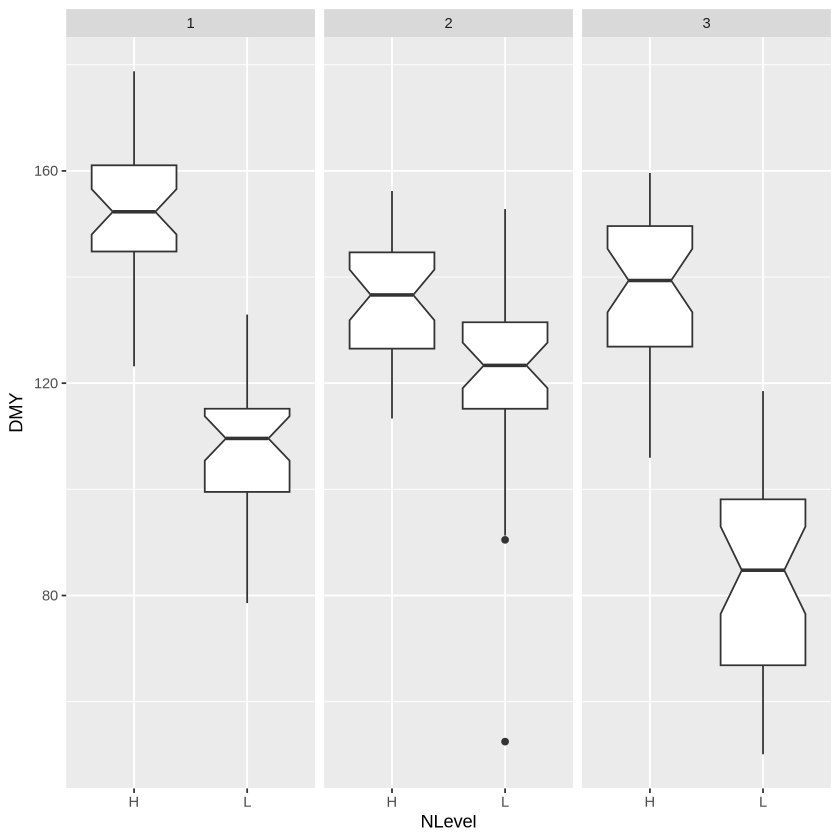

In [5]:
ggplot(Data, aes(NLevel, DMY)) +
geom_boxplot(notch=TRUE) +
facet_grid( ~ Replicate)

### Q 1 (2.5p)
Observe the boxplots and calculate the mean yield per N treatment. Hint: you can use the tidyverse commands group_by() and summarize() use in ED2020_08 (1p). What is the approximate yield advantage of the high N treatment (0.5p) and would you consider this as relevant (0.5p)? Is there an observable replication effect with regard to the difference between the treatments (0.5p)? 

In [ ]:
#Anwer Q 1 here
# na.rm = TRUE because of the one missing value, otherwise the mean of L is NA
Data |> group_by(NLevel) |> summarize(mean = mean(DMY, na.rm = TRUE))
Data |> group_by(Replicate, NLevel) |> summarize(mean = mean(DMY, na.rm = TRUE))
# mean yield: high N = 142.2 dt/ha, low N = 104.0 dt/ha
# so high N gives about 38 dt/ha more, thats around 37% more yield. i would say this is
# relevant, its a big difference.
# yes there is a replication effect: the difference between H and L is not the same in
# every replicate. in rep 1 its about 45 dt/ha, in rep 2 only 15 dt/ha (low N is quite
# high there) and in rep 3 about 55 dt/ha (low N is very low there). you also see this
# in the boxplots.

Plot the arrangement of the design using ggdesplot

Warning message in Ops.factor(Row, Range):
“‘+’ not meaningful for factors”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_text()`).”


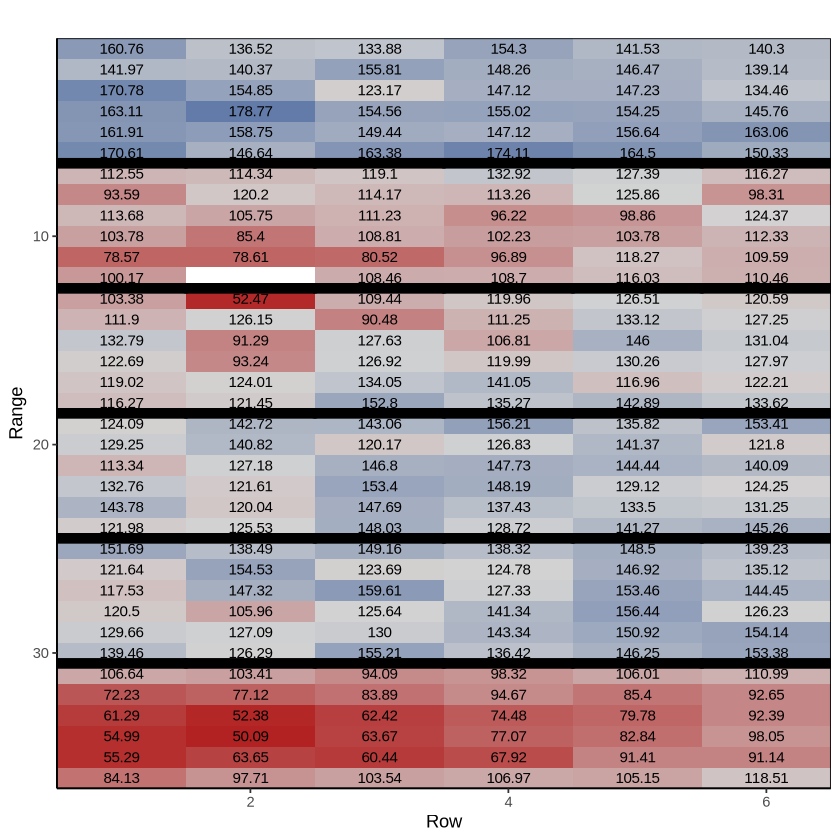

In [7]:

YieldMap <- ggdesplot(DMY ~ Row + Range,
               data = Data,
               text = DMY,
               out1 = MainPlot,
               show.key = FALSE,
               flip = T,
               ticks = TRUE,
               cex = 0.8,
               shorten = FALSE,
               main = "")
YieldMap


Run the mixed model. Here we have to use na.exclude to exclude but not omit the plot with the missing values. With na.omit (the default) the residual plotting would not work because of different numbers of rows in the original data frame compared to the residuals.

In [8]:
mix1 <- lmer(DMY ~ Genotype + NLevel + Genotype:NLevel + Replicate + (1|MainPlot), data = Data, na.action = na.exclude)
print(anova(mix1)) #uses the anova function of lmerTest

Type III Analysis of Variance Table with Satterthwaite's method
                 Sum Sq Mean Sq NumDF   DenDF F value    Pr(>F)    
Genotype        17265.2  493.29    35 139.001  2.7836 1.204e-05 ***
NLevel           1812.7 1812.65     1   2.001 10.2286   0.08539 .  
Replicate         353.6  176.80     2   2.000  0.9976   0.50059    
Genotype:NLevel  4513.4  128.95    35 139.001  0.7277   0.86287    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


This gives the same results as in the part 1 of the exercise.

## Retrieve fitted values and rediduals an add them to the data
Retrieve the fitted values, the residuals and identify exteme points.


Extract the fitted values and add them to the Data 

In [9]:
Data$Fit<-fitted(mix1)

Extract the residuals and standardize them by dividing them by their standard deviation and add them to the Data 

In [10]:
Data$StdRes<-resid(mix1, scaled=TRUE)

For this exercise we consider not to do a transformation as the experimenter also did not do so. We can identify the extreme points in your data frame using the code below. The command simply checks, if the standardized residuals exceed a certain standard deviation. Here we would like to identify the 5% of the values that fall into the extreme tails of a normal standard distribution. We know that this is 1.96 standard deviations above and below the mean in case of a normally distributed very large sample. In R, we can calculate the appropriate standard deviation threshold for any given proportion of outliers using –qnorm(x/2), where x is the proportion of extreme observations (false positives) accepted and ½ accounts for the two tails in a two-tailed distribution. In our case we set 0.05 for x. 
While qnorm() gives the threshold value, abs(StdRes) > -qnorm(0.05/2) asks, if the absolute values of the each standardized residual is larger or smaller than this value. The function as.logical() retains TRUE in case the value is larger and FALSE, otherwise. Accordingly, out.05 is a logical vector holding the extreme outliers as TRUE. As the original dataframe, as well as the output of the residuals and fitted values have the same length and sorting order, we can now use this logical vector, call it Outliers_05 and attach it to the data using mutate(). To find the research plots identified as outliers, we simply filter for "Outlier == TRUE". 


In [11]:
#Identify extreme points
upper.tail.05<-0.05/2
upper.tail.05
P.05<- -qnorm(upper.tail.05) #Probability band containing 95% of the data, of a normally distributed, very large sample
P.05

# Identify points beyond ±1.96 SD and add them to the data
Data <- Data %>%
  mutate(Outlier_05 = abs(StdRes) > P.05)

Out.05<-Data |> filter(Outlier_05 == TRUE) |> dplyr::select(SubPlot, MainPlot, Row, Range, NLevel, Genotype, Entry, DMY)
Out.05


[1] 0.025

[1] 1.959964

SubPlot,MainPlot,Row,Range,NLevel,Genotype,Entry,DMY
<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>
62,2,2,11,L,PB40R x UH007,30,78.61
74,3,2,13,L,B97 x UH007,36,52.47
216,6,6,36,L,B97 x UH007,36,118.51


A better way to identify extreme points is to use Chauvenet’s criterion. This criterion aims to identify a probability band around the residual mean that should reasonably contain all N samples of a data set. A detailed explanation how the metric is derived can be found here (https://en.wikipedia.org/wiki/Chauvenet%27s_criterion). In short, the probability P.CC represented the probability of outliers in one tail of the normal distribution 
P_CC = 1/4N
Where N is the number of samples (i.e. the number of residuals). Using this we can calculate the threshold in standard deviations above the mean above which we would expect outliers. 

In [12]:
N<-length(Data$StdRes) #The number of observations
upper.tail.Chauv<-1/(4*N) #the probability of extreme points according Chauvenet’s criterion
upper.tail.Chauv
P.CC<- -qnorm(upper.tail.Chauv) #The threshold (in standard deviations) above which extremes are expected according to Chauvenet's criterion
P.CC

# Identify points beyond ±1.96 SD and add them to the data
Data <- Data %>%
  mutate(Outlier_CC = abs(StdRes) > P.CC)

Out.CC<-Data |> filter(Outlier_CC == TRUE) |> dplyr::select(SubPlot, MainPlot, Row, Range, NLevel, Genotype, Entry, DMY)
Out.CC

[1] 0.001157407

[1] 3.046553

SubPlot,MainPlot,Row,Range,NLevel,Genotype,Entry,DMY
<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>
74,3,2,13,L,B97 x UH007,36,52.47
216,6,6,36,L,B97 x UH007,36,118.51


Now we have identified the pionts out of the band between +- 1.96 and +- 3.04 standard deviations (Chauvenet’s criterion)

As we have no good reason, to remove the outliers, we keep them in and first try to explain other nuisance factors which might affect the treatments-values.      

### Evaluate the residuals distributions in lmer()
A standard way to plot residual vs. fitted values is as follows

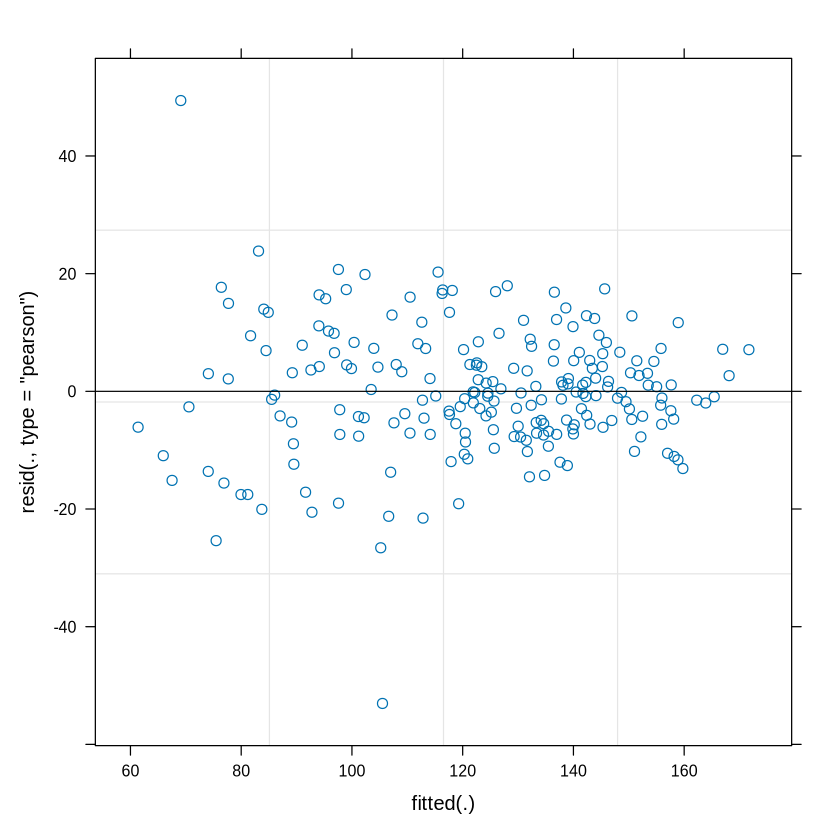

In [13]:
plot(mix1)

*Figure: Absolute residuals vs. fittes values of the mix 1 model*

To add additional information into the plot, we use the information about Outliers_CC storred with the data.

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


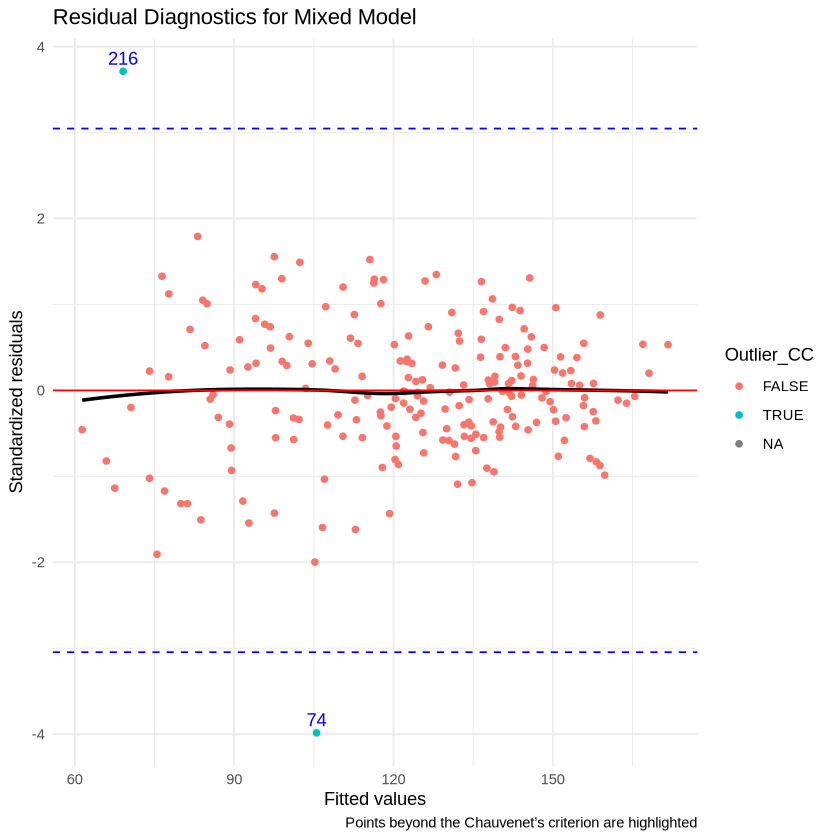

In [14]:
ggplot(Data, aes(x = Fit, y = StdRes)) +
  geom_point(aes(color = Outlier_CC)) +
  geom_smooth(method = "loess", se = FALSE, color = "black") +
  geom_hline(yintercept = 0, color = "red") +
  geom_hline(yintercept = c(-P.CC, P.CC), color = "blue", linetype = "dashed") + #P.CC gives the theshold in standard deviations
  geom_text(data = subset(Data, Outlier_CC),
            aes(label = SubPlot), color = "blue", vjust = -0.5) +
  labs(x = "Fitted values", y = "Standardized residuals",
       title = "Residual Diagnostics for Mixed Model",
       caption = "Points beyond the Chauvenet’s criterion are highlighted") +
  theme_minimal()


Figure: Standardized residuals vs. fitted values including the identification of outliers falling beyond the threshold (blue lines) given by Chauvenet's criterion. The SupPlot Id is given. The black, solid line is a smooth loess curve fitted to the scatter plot.

## Q 2 (2p)
The identification of outliers helps to detect mistakes during data recording and processing. Visit the Out.CC table above. Which genotypes (and entries) in which Nitrogen Level were identified as outliers (0.5p).

Visit the YieldMap (ggdesplot() graphic above), adjust it to display the Entry numbers, name it EntryMap and plot it (1 p). Also check how the NLevels are distributed in the design (no plot needed). 
Visit the two "extreme recordings" of Entry 36 (Genotype B97xUH007; Out.CC) in your new design plot and explain why they were identified as outliers (0.5p). Hint: you can use row and range in Out.CC to find them. 

In [ ]:
#Answer Q2 here
Out.CC
# both outliers are B97 x UH007 (entry 36) under low N: subplot 74 (rep 2, row 2,
# range 13) with 52.47 dt/ha and subplot 216 (rep 3, row 6, range 36) with 118.51 dt/ha

EntryMap <- ggdesplot(DMY ~ Row + Range,
               data = Data,
               text = Entry,
               out1 = MainPlot,
               show.key = FALSE,
               flip = T,
               ticks = TRUE,
               cex = 0.8,
               shorten = FALSE,
               main = "")
EntryMap

Data |> count(MainPlot, NLevel)
# the N levels are always on a whole main plot (6 ranges): main plot 1, 4 and 5 are high
# N, main plot 2, 3 and 6 are low N. so every replicate has one H and one L main plot.

# plot 74 (row 2, range 13) is much lower than the plots around it. its right next to
# the plot with zero yield (the NA), so probably something damaged the plants there.
# plot 216 (row 6, range 36) is much higher than the other plots in main plot 6. its in
# the corner at the edge of the field, so probably a border effect.

### Add additional explaining factors to control the spatial variablilty in the field
THE AIM OF THIS EXERCIES IS TO GET YOU AQCUIANTED WITH TESTING THE SIGNIFICANCE OF ADDITIONAL FACTORS IN THE MODEL. 

Additional explaining variables can be added in the random term of the model or in the fixed term. 
Looking at the YieldMap, we can see that those ranges next to the buffer between the high and low nitrogen treatment have often a higher yield. This is particularly visible for the low nitrogen treatment at its border to the high nitrogen treatment (range 7, 18, 31) or the outer field (range 26).

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_text()`).”


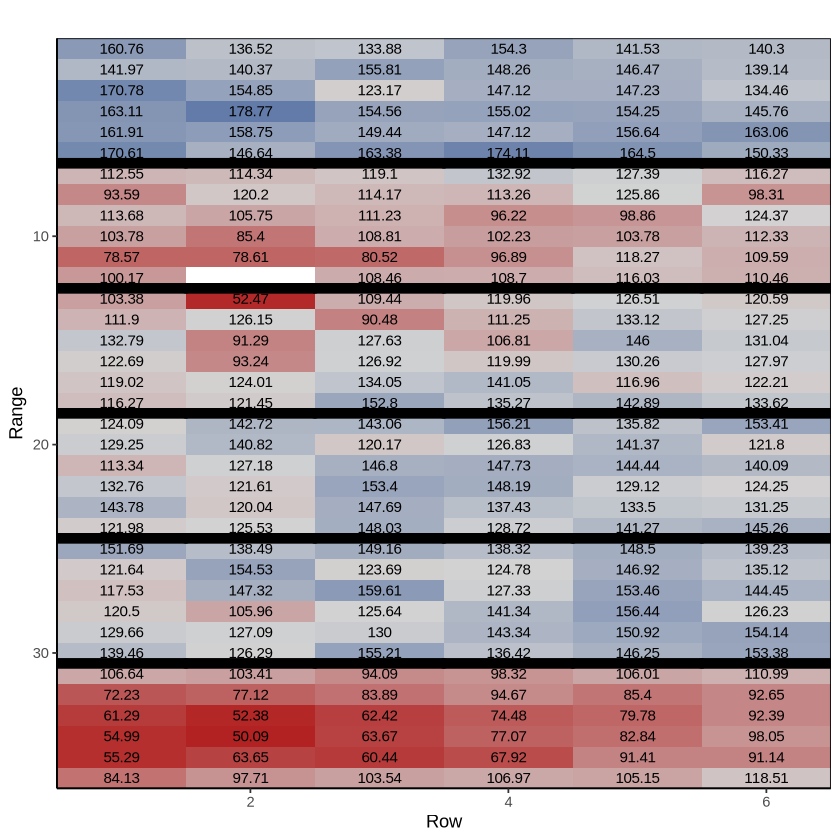

In [16]:
YieldMap

#### Adding factors to the random term
As we observe some range effects, we add range within replication as a random term. 

In [17]:
mix2 <- lmer(DMY ~ Genotype + NLevel + Genotype:NLevel + Replicate + (1|MainPlot/Range), data = Data, na.action = na.exclude)
print(anova(mix2))

Type III Analysis of Variance Table with Satterthwaite's method
                 Sum Sq Mean Sq NumDF   DenDF F value    Pr(>F)    
Genotype        13692.6  391.22    35 122.732  2.7626 2.093e-05 ***
NLevel           1448.3 1448.28     1   2.001 10.2270   0.08541 .  
Replicate         283.6  141.80     2   2.000  1.0013   0.49967    
Genotype:NLevel  3054.6   87.28    35 122.732  0.6163   0.95030    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


We can use the likelihood ratio tests to formally compare the two models. The more complex model mix 2 is nested within the simpler model mix 1. The p-value from the χ2 distribution indicates, if the more complex model is significantly differing from the simpler one.

In [18]:
print(anova(mix1, mix2))

refitting model(s) with ML (instead of REML)



Data: Data
Models:
mix1: DMY ~ Genotype + NLevel + Genotype:NLevel + Replicate + (1 | MainPlot)
mix2: DMY ~ Genotype + NLevel + Genotype:NLevel + Replicate + (1 | MainPlot/Range)
     npar    AIC    BIC  logLik -2*log(L)  Chisq Df Pr(>Chisq)    
mix1   76 1806.0 2062.2 -827.01    1654.0                         
mix2   77 1790.2 2049.7 -818.08    1636.2 17.842  1  2.401e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### Q 3 (1p)
Which model (mix1 or mix2) do you prefer based on the anova(mix1, mix2) (0.5p)? Based on the guidelines in Table 3 of the Skript, how strong is the evidence against the model with higher BIC (0.5p)? 

In [ ]:
### Answer Q3 here
# i prefer mix2. the chi-square test is significant (p = 2.4e-05), so the model with
# range within main plot is better. also AIC and BIC are lower for mix2.
# BIC difference = 2062.2 - 2049.7 = 12.5, thats > 10, so very strong evidence against
# mix1 (the model with the higher BIC).

#### Adding factors to the fixed term
It is not very clear, but there might be some row effects, too. Let's add a row effect to the fixed term. We have only 6 rows in the design and they are spanning across all nitrogen treatments. For this reason, we add them to the fix term.

### Q 4 (1.5p)
Adjust the model mix2 by adding a fixed Row effect but keep all other parameters in the model constant and name the model mix3 (1p). Examine the ANOVA table of mix3. Would you keep the Row effect in the model (0.5p)?

In [ ]:
### Answer Q4 here
mix3 <- lmer(DMY ~ Genotype + NLevel + Genotype:NLevel + Row + Replicate + (1|MainPlot/Range), data = Data, na.action = na.exclude)
print(anova(mix3))
# Row is highly significant in the anova of mix3 (p = 1.9e-08), so yes i would keep the
# Row effect in the model, it explains part of the differences in the field.

### Remove exptreme points

It is always a good idea to consider the removal of extreme outliers. Often, these are mistakes in the sampling process which can strongly affect the results of the ANOVA. We should check the residuals again and identify outliers for mix3. However, we skip this part. We tested it for you and nothing changed concerning the extremes identified based on the Chauvenet’s criterion.

Let’s replace these extreme points (wherever Outlier_CC is set TRUE) by missing values (NA) using mutate to generate a new vector in the Data tibble called DMY.NA (dry matter yield with missing values). 

In [21]:
Data <- Data %>%
  mutate(
    DMY.NA = if_else(Outlier_CC, NA, DMY)
  )
#Quick check that it worked
Data |> filter(Outlier_CC == TRUE) |> dplyr::select(SubPlot, MainPlot, Row, Range, NLevel, Genotype, Entry, DMY, DMY.NA)

SubPlot,MainPlot,Row,Range,NLevel,Genotype,Entry,DMY,DMY.NA
<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>
74,3,2,13,L,B97 x UH007,36,52.47,NA
216,6,6,36,L,B97 x UH007,36,118.51,NA


We run a fourth model using DMY.NA instead of DMY.

In [22]:
mix4 <- lmer(DMY.NA ~ Genotype + NLevel + Genotype:NLevel + Row + Replicate + (1| MainPlot/Range), data = Data, na.action = na.exclude)
print(anova(mix4))

Type III Analysis of Variance Table with Satterthwaite's method
                 Sum Sq Mean Sq NumDF   DenDF F value    Pr(>F)    
Genotype        13052.2  372.92    35 114.643  4.5650 3.723e-10 ***
NLevel            750.1  750.09     1   2.001  9.1820   0.09378 .  
Row              4152.7  830.53     5 104.381 10.1668 5.927e-08 ***
Replicate         158.5   79.26     2   2.000  0.9702   0.50756    
Genotype:NLevel  2971.1   84.89    35 114.581  1.0391   0.42502    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


## Decide which factors to summarize and estimate marginal means
Let mix4 be our final model. The ANOVA table gives us guidelines which factors to summarize and which to average over.

##### Q5 (2p)
Conclude based on the ANOVA table for which factors or their interaction to present the marginal means and to perform post-hoc tests (2p). Visit Table 4 in the Skript for help. 
Consider not only the significance threshold (say 0.05 significance level), but also the relevance of the effects for your decision.


In [ ]:
#Answer Q5 here
# genotype is highly significant (p = 3.7e-10), so i present the marginal means of the
# genotypes (averaged over N) and do the post-hoc tests for them.
# genotype x N is not significant (p = 0.43), so no means for the combinations.
# NLevel is not significant at 0.05 (p = 0.094), but the effect is big and relevant
# (about 38 dt/ha). it only has 2 error df because its the main plot factor, so its hard
# to get significant. so i would still present the two N means and give the p-value
# (p < 0.1). no post-hoc test needed there, there are only 2 levels.
# row and replicate are only in the model because of the field (design), so no means
# for them.

We calculate the marginal means for the factor "Genotype" with emmeans() averaging over all other factors. As we involve interactions, there is a warning.
This is the same approach like in Exercise 3 just using mix 4 with incomplete blocking and missing exptreme points instead of mix 1 on the original data. 
Note that the standard error of the mean (SE) differs because i) we have incomplete blocking because of row and range and ii) we have two removed outliers for B97 x UH007. 

In [24]:
GenMean4<-emmeans(mix4, ~Genotype) 
GenMean4

Warning message:
“Model has 216 prior weights, but we recovered 213 rows of data.
So prior weights were ignored.”
NOTE: Results may be misleading due to involvement in interactions



 Genotype                emmean   SE   df lower.CL upper.CL
 A310 x UH007               115 7.41 3.83     93.9      136
 A347 x UH007               111 7.44 3.90     90.0      132
 B100 x UH007               123 7.44 3.89    102.0      144
 B73 x UH007                131 7.44 3.90    109.7      151
 B84 x UH007                131 7.42 3.87    110.3      152
 B89 x UH007                120 7.41 3.84     99.4      141
 B97 x UH007                114 8.52 6.62     93.7      134
 EC169 x UH007              128 7.43 3.87    107.6      149
 EP52 x UH007               132 7.45 3.93    111.1      153
 EZ11A x UH007              131 7.42 3.86    110.1      152
 EZ37 x UH007               125 7.44 3.89    104.3      146
 EZ47 x UH007               120 7.41 3.83     99.5      141
 F1808 x UH007              139 7.44 3.90    117.8      160
 F7028 x UH007              114 7.42 3.87     93.1      135
 F894 x UH007               135 7.44 3.91    113.7      155
 F912 x UH007               127 7.42 3.8

# Post hoc tests
## Adjusting for multiple pairwise comparisons
Suppose we would like to do all pairwise comparisons, we need a Tukey or Sidak adjustment. The package emmeans() adjust per default using the Tukey HSD with an experiment-wise error rate of 0.05. 

By using pairwise, the function “emmeans” does also report pairwise contrast. You can, thus, compare each pair separately. 

In [25]:
#Obtain the marginal means and pairwise contrasts. THIS TAKES LONG TO RUN; i.e. 5 minutes
#GenContrast<-emmeans(mix1, pairwise~Genotype,  parallel = TRUE) #We use mix 1 as it is too time consuming to run mix 4.



In [26]:
#saveRDS(GenContrast, file="../data/GenContrastSidak.rds")


In [27]:
GenContrast<-readRDS(file="../data/GenContrastSidak.rds")
str(GenContrast)


$emmeans
'emmGrid' object with variables:
    Genotype = A310 x UH007, A347 x UH007, B100 x UH007, B73 x UH007, B84 x UH007, B89 x UH007, B97 x UH007, EC169 x UH007, EP52 x UH007, ..., W64A x UH007

$contrasts
'emmGrid' object with variables:
    contrast = A310 x UH007 - A347 x UH007, A310 x UH007 - B100 x UH007, A310 x UH007 - B73 x UH007, A310 x UH007 - B84 x UH007, A310 x UH007 - B89 x UH007, A310 x UH007 - B97 x UH007, A310 x UH007 - EC169 x UH007, A310 x UH007 - EP52 x UH007, A310 x UH007 - EZ11A x UH007, ..., UH250 x UH007 - W64A x UH007



In [28]:
head(GenContrast$contrasts)

Note: adjust = "tukey" was changed to "sidak"
because "tukey" is only appropriate for one set of pairwise comparisons



 contrast                    estimate   SE  df t.ratio p.value
 A310 x UH007 - A347 x UH007     6.79 7.69 139   0.883  0.9424
 A310 x UH007 - B100 x UH007    -5.73 7.69 139  -0.746  0.9744
 A310 x UH007 - B73 x UH007    -17.23 7.69 139  -2.242  0.1489
 A310 x UH007 - B84 x UH007    -15.83 7.69 139  -2.060  0.2236
 A310 x UH007 - B89 x UH007     -5.08 7.69 139  -0.661  0.9861
 A310 x UH007 - B97 x UH007      1.89 7.69 139   0.246  0.9999

Results are averaged over the levels of: NLevel, Replicate 
Degrees-of-freedom method: kenward-roger 
P value adjustment: sidak method for 6 tests 

You can also calculate the average standard error of the difference between all pairs. We will use it later as unified value to evaluate differences between any pair of genotypes in the set.

In [29]:
#GenContrastsSidak.df<-as.data.frame(GenContrastsSidak$contrasts)

In [30]:
#saveRDS(GenContrastsSidak.df, file="../data/GenContrastSidak.df.rds")


In [31]:
GenContrastsSidak.df<-readRDS(file="../data/GenContrastSidak.df.rds")

You can pull out all pairs of treatments which are significantly differing from each other. One could use also a compact letter display using
*GenMean1<-emmeans(mix1, ~Genotype)* and *multcomp::cld(GenMean1)* 
But this takes a long time to run.

In [32]:
GenContrastsSidak.df |> filter(p.value <= 0.05)

contrast,estimate,SE,df,t.ratio,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
F1808 x UH007 - N25 x UH007,32.77500,7.685802,139,4.264356,0.01594021
N25 x UH007 - UH250 x UH007,-33.44500,7.685802,139,-4.351530,0.01165680
(Os420_RootABA1+ x UH007) - UH250 x UH007,-30.57167,7.685802,139,-3.977680,0.04204074


## Multiple comparison to a common control using Dunnett-style contrasts
To compare genotypes to a control genotype, you can use Dunnett-style treatment vs. control test. Here we chose B73 x UH007 as common check to compare the other treatments to. The famous inbred line (B73) was introduced into many breeding programmes based on its very good combining ability. It was also the first maize genotype, which was fully sequenced. With the treatment vs. control test, we aim to find hybrids which outperform this check. 

In [33]:
#TreatContr4<- contrast(GenMean4, "trt.vs.ctrl", ref = 4) #the reference (ref) is B73 x UH007 with is number 4 in the list. 

In [34]:
#saveRDS(TreatContr4, file="../data/TreatContr4.rds")

In [35]:
TreatContr4<-readRDS(file="../data/TreatContr4.rds")

In [36]:
TreatContr4.df<-as_tibble(TreatContr4)

In [45]:
head(TreatContr4.df)

contrast,estimate,SE,df,t.ratio,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A310 x UH007 - B73 x UH007,-15.7898921,5.648563,116.9407,-2.7953823,0.1272242
A347 x UH007 - B73 x UH007,-19.7677793,5.744328,117.7693,-3.4412691,0.0216380
B100 x UH007 - B73 x UH007,-7.7488846,5.655272,117.4612,-1.3702054,0.9055754
B84 x UH007 - B73 x UH007,0.5804798,5.681034,117.1431,0.1021785,1.0000000
B89 x UH007 - B73 x UH007,-10.2516408,5.690119,118.5102,-1.8016566,0.6816710
B97 x UH007 - B73 x UH007,-16.4934876,7.074249,119.5053,-2.3314824,0.3324780


Now we filter for those pairs which are having a significant difference according to after adjusting for multiple pairwise comparsisons

In [38]:
TreatContr4.df |> filter(p.value <= 0.05)

contrast,estimate,SE,df,t.ratio,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A347 x UH007 - B73 x UH007,-19.76778,5.744328,117.7693,-3.441269,0.021638002
N25 x UH007 - B73 x UH007,-24.28926,5.753892,120.8116,-4.221361,0.001482829
N6 x UH007 - B73 x UH007,-18.62504,5.637122,117.4033,-3.303999,0.032733272
(Os420_RootABA1- x UH007) - B73 x UH007,-20.73057,5.747670,119.4422,-3.606778,0.012781566
(Os420_RootABA1+ x UH007) - B73 x UH007,-20.95099,5.580772,114.8595,-3.754139,0.007969165


### Q 6 (2p)
The table above shows the pairwise comparisons to the common check B73 x UH007 which were significant at the 0.05 experiment-wise probability level. Is such a comparison allowed? Justify your answer given what we discussed in for post-hoc test assumptions and decisions taken when making an experimental design (1p). What could have been done during the design process of the experiment? Think of the replications of the check variety and what we discussed in the lecture about post-hoc tests in relation to standard errors (1p).

In [ ]:
#Answer Q6 here
# the dunnett test itself is ok, it adjusts for all the comparisons to one check. but it
# is only really allowed if the check was chosen before the experiment (planned). here
# B73 was just one of the 36 hybrids with the same number of replications as all others
# and it was picked as check afterwards, so the comparison wasnt planned in the design.
# in the design you could have planned B73 as check from the start and replicated it
# more often (e.g. several times in every block). then its mean is more precise, the
# standard error of the differences to the check is smaller and differences to the
# check are easier to detect.

## Planned pairwise comparisons
Finally, we could look at on particular pair of genotypes within the whole set. We grew two lines which differed only for a quantitative traits locus controlling root architecture, RootABA1 + and -. The pair can be compared using the “at” statement in *emmeans()*. This way you do not have to run all pairwise comparisons. For this comparison the LSD is used as critical value.

In [40]:
OnePair<-emmeans(mix4, "Genotype", at = list(Genotype = c("Os420_RootABA1- x UH007", "Os420_RootABA1+ x UH007")))
OnePair

Warning message:
“Model has 216 prior weights, but we recovered 213 rows of data.
So prior weights were ignored.”
NOTE: Results may be misleading due to involvement in interactions



 Genotype                emmean   SE   df lower.CL upper.CL
 Os420_RootABA1- x UH007    110 7.42 3.85     89.0      131
 Os420_RootABA1+ x UH007    110 7.44 3.90     88.8      131

Results are averaged over the levels of: NLevel, Row, Replicate 
Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 

In [41]:
pairs(OnePair)

 contrast                                              estimate   SE  df
 (Os420_RootABA1- x UH007) - (Os420_RootABA1+ x UH007)     0.22 5.73 118
 t.ratio p.value
   0.038  0.9694

Results are averaged over the levels of: NLevel, Row, Replicate 
Degrees-of-freedom method: kenward-roger 

### Q 7 (1p)
Based on these results (pairs()), do you think the two genotypes differ? Explain why you came to this conclusion (0.5p). Explain in your own words, why it is appropriate to compare the means of the two lines without adjusting for an experiment-wise multiple comparisons (0.5p)? 


In [ ]:
#Answer Q7 here
# no, i dont think they differ. the difference is only 0.22 dt/ha with a SE of 5.73 and
# p = 0.97, so far away from significant.
# no adjustment is needed because its only one comparison and it was planned before the
# experiment (the two lines were grown on purpose to compare them, they only differ in
# one QTL). with only one test there is no multiple testing problem, so the normal LSD
# (t-test) is fine.

## Prepare data for reporting

To report your anova you can use the library broom

In [43]:
library(broom)
#Use this table to obtain the denominator degrees for freedom needed below
names(anova(mix4))

# Tidy ANOVA table
 tidy(anova(mix4))

[1] "Sum Sq"  "Mean Sq" "NumDF"   "DenDF"   "F value" "Pr(>F)"

Warning message:
“The column names NumDF and DenDF in ANOVA output were not recognized or
transformed.”


term,sumsq,meansq,NumDF,DenDF,statistic,p.value
<chr>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Genotype,13052.2086,372.92025,35,114.642951,4.5650102,3.723344e-10
NLevel,750.0863,750.08631,1,2.000918,9.1819944,9.377918e-02
Row,4152.6638,830.53275,5,104.381198,10.1667595,5.927089e-08
Replicate,158.5170,79.25851,2,2.000000,0.9702233,5.075567e-01
Genotype:NLevel,2971.1060,84.88874,35,114.581375,1.0391444,4.250207e-01


In [44]:
anova_summary <- tidy(anova(mix4)) |>
  mutate(
    p.value = formatC(p.value, format = "f", digits = 3),  # normal numbers
    NumDF = signif(NumDF, 3),
    DenDF = signif(DenDF, 3),
    meansq = signif(meansq, 3),
    sumsq = round(sumsq, 0),
    statistic = round(statistic, 1)
  )
anova_summary

Warning message:
“The column names NumDF and DenDF in ANOVA output were not recognized or
transformed.”


term,sumsq,meansq,NumDF,DenDF,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Genotype,13052,373.0,35,115,4.6,0.000
NLevel,750,750.0,1,2,9.2,0.094
Row,4153,831.0,5,104,10.2,0.000
Replicate,159,79.3,2,2,1.0,0.508
Genotype:NLevel,2971,84.9,35,115,1.0,0.425
